In [14]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selection_result(results, ax, budget=None, label=None, color=None):
    import scipy.stats as sps

    if budget is None:
        budget = results.shape[-1]

    def ci(y):
        br = sps.bootstrap((y,), np.mean, vectorized=True)
        ci_l = br.confidence_interval.low
        ci_u = br.confidence_interval.high
        return ci_l, ci_u

    iters = np.arange(0, budget, 1)
    agg_value = results.mean(axis=0)[:budget].ravel()
    _ci_lb, _ci_ub = ci(results)[:budget]

    line, *_ = ax.plot(iters, agg_value, linewidth=1.5, label=label, color=color)

    ax.plot(iters, _ci_lb, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.plot(iters, _ci_ub, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.fill_between(iters, _ci_lb, _ci_ub, alpha=0.3, color=line.get_color())


In [15]:
import torch
import numpy as np


def get_res_p(_path):
    arr = np.loadtxt(_path)
    return get_res_o(arr)

def get_res_o(arr):
    return torch.from_numpy(arr).cummax(axis=-1).values.detach().numpy()

In [16]:
# tidyhebo
tidyhebo_res = get_res_p("data/edbo_features_tidyhebo.txt")

# LogEI
qlogei = get_res_p("data/edbo_features_default_qlogei.txt")
# qlogei = get_res_p("data/edbo_features_matern52_dimscaled.txt")

# edbo results
import pandas as pd
df = pd.read_csv("data/arylation_bo_results_GP-EI_bs=5.csv", index_col=0)
edbo_res = df.values
edbo_res = torch.from_numpy(edbo_res).cummax(axis=1).values.detach().numpy()

# random
df = pd.read_csv("data/direct_arylation_embeddings.csv", index_col=0)
random_out = [df.sample(100)["yield"].to_numpy() for _ in range(50)]
random_out = np.vstack(random_out)
random_res = torch.from_numpy(random_out).cummax(axis=1).values.detach().numpy()


/home/jnarbert/miniforge3/envs/tidyhebo/lib/python3.11/site-packages/scipy/stats/_resampling.py:147: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/home/jnarbert/miniforge3/envs/tidyhebo/lib/python3.11/site-packages/scipy/_lib/_util.py:352: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


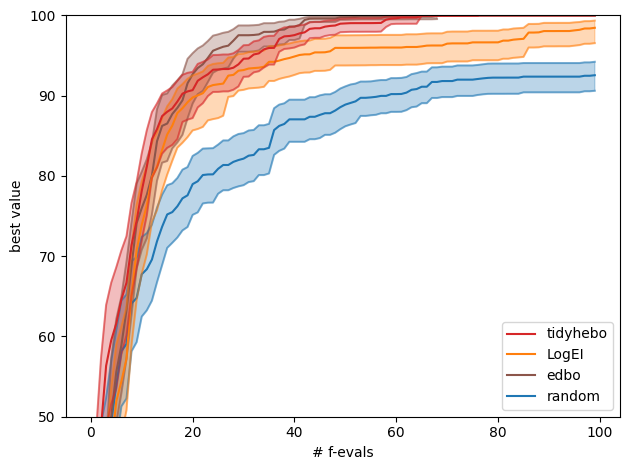

In [13]:
import matplotlib.pyplot as plt


fig = plt.gcf()
ax = plt.gca()

plot_selection_result(random_res, ax, budget=100, label="random", color="tab:blue")
plot_selection_result(edbo_res, ax, budget=100, label="edbo", color="tab:brown")
plot_selection_result(qlogei, ax, budget=100, label="LogEI", color="tab:orange")
plot_selection_result(tidyhebo_res, ax, budget=100, label="tidyhebo", color="tab:red")

# fig.suptitle("Сходимость моделей (direct arylation)")
ax.set_ylabel("best value")
ax.set_xlabel("# f-evals")
ax.set_ylim(top=100, bottom=50)

handles, labels = ax.get_legend_handles_labels()
ax.legend(reversed(handles), reversed(labels));
ax.figure.tight_layout()